# 03 · Zero-shot benchmark

Two time-series foundation models, TimesFM 3 and Timestral, forecast
precipitation at single pixels with no training on this data, next to
persistence, climatology and an extrapolation nowcast. This is a smoke run on
validation days: 3 days for the 15-minute regime (4,800 samples per lead) and
July–August 2025 for the 6-hour regime (24,800 samples per lead).

**Summary**

- **The first hour belongs to the foundation models.** At 15 minutes every
  one of them beats persistence and extrapolation (CRPS skill against
  climatology +0.35 to +0.53, against +0.16 for both baselines). At one hour
  most are still slightly above climatology (+0.02 to +0.12) while the
  baselines are far below it (−0.47 and −0.58).
- **From 90 minutes on, nothing beats climatology** by more than 0.02 in the
  15-minute regime. In the 6-hour regime the models are within ±0.06 of climatology at
  every lead: a pixel's own history says little about the next 6 to 48 hours.
- **Neighbouring cells help most.** Adding the eight surrounding cells as
  extra variates is the best variant for both models (Timestral 209M: +0.53
  at 15 minutes, against +0.41 without them). Satellite and solar covariates
  change little; a log1p transform of the target hurts Timestral at every
  lead past 15 minutes.
- **Size barely matters.** The four Timestral sizes, 5M to 209M parameters,
  are within about 0.04 of each other at every lead.
- **Events.** At 1 mm/h and 15 minutes the models reach a CSI of 0.53 to
  0.61, against 0.48 for persistence. From 45 minutes on, persistence and
  extrapolation have the higher CSI at both thresholds: the medians of the
  foundation models drift towards dry, which scores well on CRPS but misses
  the rain events, and past one hour their CSI stays below 0.1.

Three days and no confidence intervals: differences of a few hundredths are
noise until the significance tests on the test window.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from arena.config import load_config
from arena.paths import project_path

cfg = load_config()
plt.rcParams.update(
    {"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9}
)
pd.options.display.float_format = "{:,.3f}".format


def summary(regime: str) -> pd.DataFrame:
    path = project_path(cfg.tsfm.summary.format(regime=regime, label="smoke"))
    table = pd.read_csv(path)
    table["lead_hours"] = table.lead_minutes / 60
    return table


a, b = summary("a"), summary("b")
print(
    f"regime A: {a.model.nunique()} models, {int(a.samples.iloc[0]):,} samples per lead"
)
print(
    f"regime B: {b.model.nunique()} models, {int(b.samples.iloc[0]):,} samples per lead"
)

regime A: 14 models, 4,800 samples per lead
regime B: 6 models, 24,800 samples per lead


## 1. What was run

Every model forecasts the same 200 evaluation pixels (40 per terrain
stratum, held-out blocks) from the same issue times, and is scored on the
same 19 quantile levels against the same observations.

| | Regime A | Regime B |
|---|---|---|
| Target | 15-minute rate (mm/h) | 6-hour total (mm) |
| Context | 7 days | 120 days |
| Leads | 15 min to 6 h | 6 h to 48 h |
| Issues | every 3 h on 15–17 July 2025 | 00 and 12 UTC, July–August 2025 |
| Baselines | persistence, climatology, extrapolation | persistence, climatology |

These are **validation days**, not the test window, and the context ends at
the issue time (hindcast; the target itself looks up to 90 minutes ahead).
No confidence intervals yet: they come with the significance tests. Treat
differences of a few hundredths in CRPS skill as noise.

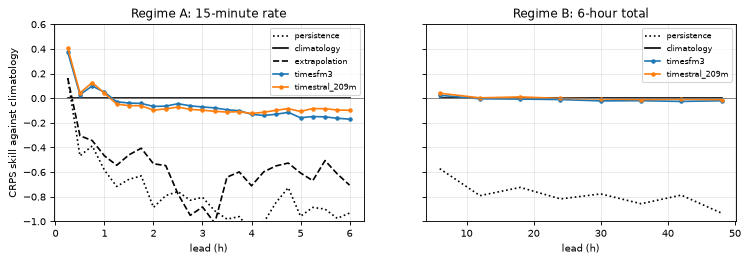

In [2]:
BASE = ["persistence", "climatology", "extrapolation"]
PLAIN = ["timesfm3", "timestral_209m"]
STYLE = {"persistence": "k:", "climatology": "k-", "extrapolation": "k--"}


def curves(table, models, ax, column="crps_skill"):
    for model in models:
        rows = table[table.model == model]
        if rows.empty:
            continue
        ax.plot(
            rows.lead_hours,
            rows[column],
            STYLE.get(model, "-"),
            marker="." if model not in STYLE else None,
            label=model,
        )
    ax.set_xlabel("lead (h)")


fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
curves(a, BASE + PLAIN, axes[0])
curves(b, BASE + PLAIN, axes[1])
axes[0].set_title("Regime A: 15-minute rate")
axes[1].set_title("Regime B: 6-hour total")
axes[0].set_ylabel("CRPS skill against climatology")
for ax in axes:
    ax.axhline(0, color="grey", lw=0.8)
    ax.legend(fontsize=7)
axes[0].set_ylim(-1, 0.6)
plt.show()

## 2. Skill against lead time

CRPS skill is 1 − CRPS / CRPS of climatology: above zero the model beats
the climatology of its cell, month and hour.

In [3]:
table = a[a.lead_minutes.isin([15, 30, 60, 120, 360])].pivot(
    index="model", columns="lead_minutes", values="crps_skill"
)
table.columns = [f"{c} min" for c in table.columns]
table.sort_values("15 min", ascending=False)

,15 min,30 min,60 min,120 min,360 min
model,,,,,
timestral_209m_neighbours,0.528,0.195,0.117,-0.027,-0.068
timesfm3_neighbours,0.453,0.119,0.102,-0.004,-0.044
timestral_209m_covariates,0.419,0.080,0.058,-0.095,-0.108
timestral_123m,0.418,0.065,0.050,-0.105,-0.137
timestral_209m,0.409,0.042,0.040,-0.097,-0.099
timestral_28m,0.409,0.029,0.050,-0.113,-0.126
timestral_5m,0.391,0.025,0.038,-0.094,-0.104
timesfm3_covariates,0.377,-0.004,0.043,-0.067,-0.056
timesfm3,0.375,0.029,0.048,-0.067,-0.170


In [4]:
table = b[b.lead_minutes.isin([360, 720, 1440, 2880])].pivot(
    index="model", columns="lead_minutes", values="crps_skill"
)
table.columns = [f"{c // 60} h" for c in table.columns]
table.sort_values("6 h", ascending=False)

,6 h,12 h,24 h,48 h
model,,,,
timestral_209m_neighbours,0.054,0.008,0.002,-0.011
timestral_209m,0.040,0.003,-0.002,-0.012
timesfm3_neighbours,0.024,-0.006,-0.009,-0.020
timesfm3,0.023,-0.005,-0.011,-0.021
climatology,0.000,0.000,0.000,0.000
persistence,-0.572,-0.791,-0.818,-0.933


## 3. Variants of the two largest models

Each variant changes one thing: a log1p transform of the target, satellite
and solar covariates, or the eight neighbouring cells as extra variates.

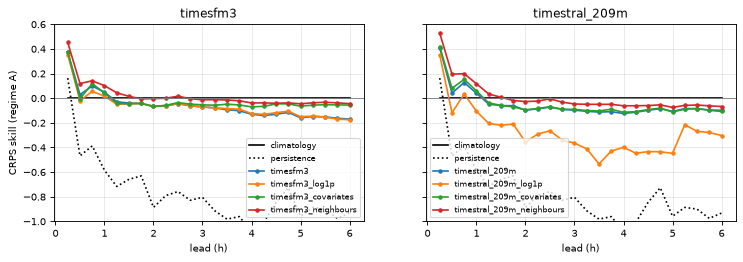

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, base in zip(axes, PLAIN, strict=True):
    variants = [base, f"{base}_log1p", f"{base}_covariates", f"{base}_neighbours"]
    curves(a, ["climatology", "persistence", *variants], ax)
    ax.set_title(base)
    ax.axhline(0, color="grey", lw=0.8)
    ax.legend(fontsize=7)
axes[0].set_ylabel("CRPS skill (regime A)")
axes[0].set_ylim(-1, 0.6)
plt.show()

## 4. Model size (Timestral)

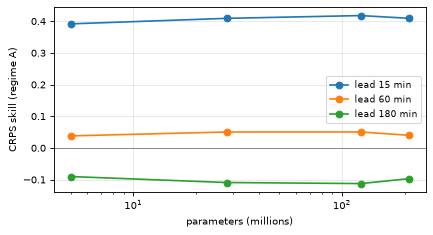

In [6]:
sizes = ["timestral_5m", "timestral_28m", "timestral_123m", "timestral_209m"]
params = [5, 28, 123, 209]
fig, ax = plt.subplots(figsize=(6, 3))
for minutes in (15, 60, 180):
    rows = a[a.lead_minutes == minutes].set_index("model").reindex(sizes)
    ax.plot(params, rows.crps_skill, marker="o", label=f"lead {minutes} min")
ax.set_xscale("log")
ax.set_xlabel("parameters (millions)")
ax.set_ylabel("CRPS skill (regime A)")
ax.axhline(0, color="grey", lw=0.8)
ax.legend(fontsize=8)
plt.show()

## 5. Events and calibration

Critical success index for rain at or above 0.1 and 1 mm/h (median forecast
as yes/no), and the share of observations inside the 90 % central interval.
Most samples are dry, and a forecast whose quantiles are all zero contains a
dry observation, so coverage near 1 says little on its own; the wet-sample
calibration comes with the reliability diagrams.

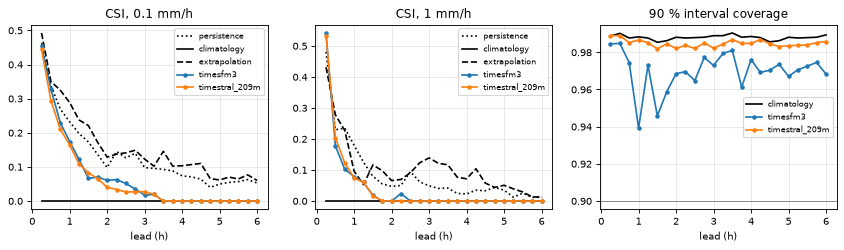

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
curves(a, BASE + PLAIN, axes[0], "csi_0.1")
curves(a, BASE + PLAIN, axes[1], "csi_1")
curves(a, ["climatology", *PLAIN], axes[2], "coverage_90")
axes[0].set_title("CSI, 0.1 mm/h")
axes[1].set_title("CSI, 1 mm/h")
axes[2].set_title("90 % interval coverage")
axes[2].axhline(0.9, color="grey", lw=0.8)
for ax in axes:
    ax.legend(fontsize=7)
plt.show()

## 6. What this means

The remaining text is written from the numbers above; see the summary at
the top. The forecast model enters regime B once its runs for the test
window are archived, and the test-window run of this notebook replaces the
validation smoke.